# Decision Trees and Neural Networks on the Census Income (Adult) Dataset

Goal: predict whether a person earns **>50K** per year.

- **Part 1 – Decision trees:** two trees at different depths, how depth affects bias and variance, and which attributes the tree splits on.
- **Part 2 – Neural networks:** three architectures with different numbers of hidden layers and nodes, a drawing of each, and a comparison of their edge weights with the decision tree.

Both parts use the **same 7 input features and the same train/test split**, so the two models can be compared directly.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix

## 1. Load the data
We keep 7 simple inputs so every input node can be labeled on the diagrams.
`sex` and `marital_status` become yes/no columns (`is_male`, `married`).

In [2]:
cols = ["age", "workclass", "fnlwgt", "education", "education_num", "marital_status",
        "occupation", "relationship", "race", "sex", "capital_gain", "capital_loss",
        "hours_per_week", "native_country", "income"]
df = pd.read_csv("data/adult.data", names=cols, skipinitialspace=True, na_values="?").dropna()

# target: 1 = earns >50K, 0 = earns <=50K
df["income"] = (df["income"] == ">50K").astype(int)

# two simple yes/no features
df["is_male"] = (df["sex"] == "Male").astype(int)
df["married"] = (df["marital_status"].str.startswith("Married")).astype(int)

features = ["age", "education_num", "hours_per_week", "capital_gain",
            "capital_loss", "is_male", "married"]
X = df[features]
y = df["income"]
print(X.shape, "| share earning >50K:", round(y.mean(), 3))
X.head()

(30162, 7) | share earning >50K: 0.249


,age,education_num,hours_per_week,capital_gain,capital_loss,is_male,married
0,39,13,40,2174,0,1,0
1,50,13,13,0,0,1,1
2,38,9,40,0,0,1,0
3,53,7,40,0,0,1,1
4,28,13,40,0,0,0,1


## 2. Train/test split and scaling
- The **decision trees** use the raw values. Trees only compare a feature against a threshold, so scaling doesn't change them, and raw values keep the splits readable (e.g. `education_num > 12.5`).
- The **neural networks** are sensitive to feature scale, so they get standardized inputs (scaler fit on the training data only).

In [3]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42, stratify=y)

scaler = StandardScaler().fit(X_train)
X_train_s = scaler.transform(X_train)
X_test_s  = scaler.transform(X_test)

In [4]:
# helper used by both parts: builds a tidy table of metrics for a dict of fitted models
def metrics_table(models, Xtr, Xte):
    rows = []
    for name, m in models.items():
        pred_train = m.predict(Xtr)
        pred_test  = m.predict(Xte)
        rows += [
            {"Model": name, "Metric": "Train accuracy",   "Score": accuracy_score(y_train, pred_train)},
            {"Model": name, "Metric": "Test accuracy",    "Score": accuracy_score(y_test, pred_test)},
            {"Model": name, "Metric": "Precision (>50K)", "Score": precision_score(y_test, pred_test)},
            {"Model": name, "Metric": "Recall (>50K)",    "Score": recall_score(y_test, pred_test)},
            {"Model": name, "Metric": "F1 (>50K)",        "Score": f1_score(y_test, pred_test)},
        ]
    return pd.DataFrame(rows)

def plot_metrics(models, Xtr, Xte, title):
    metrics = metrics_table(models, Xtr, Xte)
    plt.figure(figsize=(13, 5))
    ax = sns.barplot(data=metrics, x="Metric", y="Score", hue="Model", palette="Set2")
    for bars in ax.containers:
        ax.bar_label(bars, fmt="%.2f", fontsize=8)
    ax.set_ylim(0, 1)
    ax.set_xlabel("")
    ax.set_title(title, pad=35)
    ax.legend(loc="lower center", bbox_to_anchor=(0.5, 1.0), ncol=3, frameon=False)
    plt.tight_layout()
    plt.show()

def plot_confusion(models, Xte, title):
    labels = ["<=50K", ">50K"]
    fig, axes = plt.subplots(1, len(models), figsize=(5.3 * len(models), 4.5))
    for ax, (name, m) in zip(np.atleast_1d(axes), models.items()):
        cm = confusion_matrix(y_test, m.predict(Xte))
        sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax,
                    xticklabels=labels, yticklabels=labels, annot_kws={"size": 13})
        ax.set_xlabel("Predicted")
        ax.set_ylabel("Actual")
        ax.set_title(name, fontsize=10)
    plt.suptitle(title)
    plt.tight_layout()
    plt.show()

---
# Part 1 – Decision Trees

## 3. Two trees at different depths
We fit one shallow tree (`max_depth=2`) and one deeper tree (`max_depth=4`).
In each box: the split rule, the **gini** impurity (0 = pure node), how many training **samples** reach the node, the **value** = [count <=50K, count >50K], and the majority **class**. Orange = mostly <=50K, blue = mostly >50K, and a darker color means a purer node.

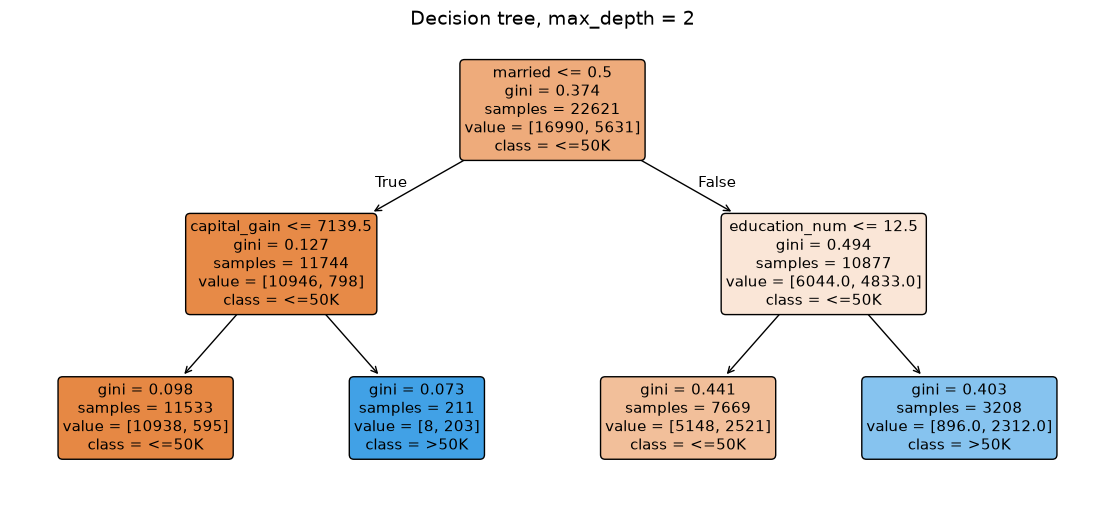

In [5]:
tree_d2 = DecisionTreeClassifier(max_depth=2, random_state=42).fit(X_train, y_train)
tree_d4 = DecisionTreeClassifier(max_depth=4, random_state=42).fit(X_train, y_train)

plt.figure(figsize=(14, 6))
plot_tree(tree_d2, feature_names=features, class_names=["<=50K", ">50K"],
          filled=True, rounded=True, fontsize=11)
plt.title("Decision tree, max_depth = 2", fontsize=14)
plt.show()

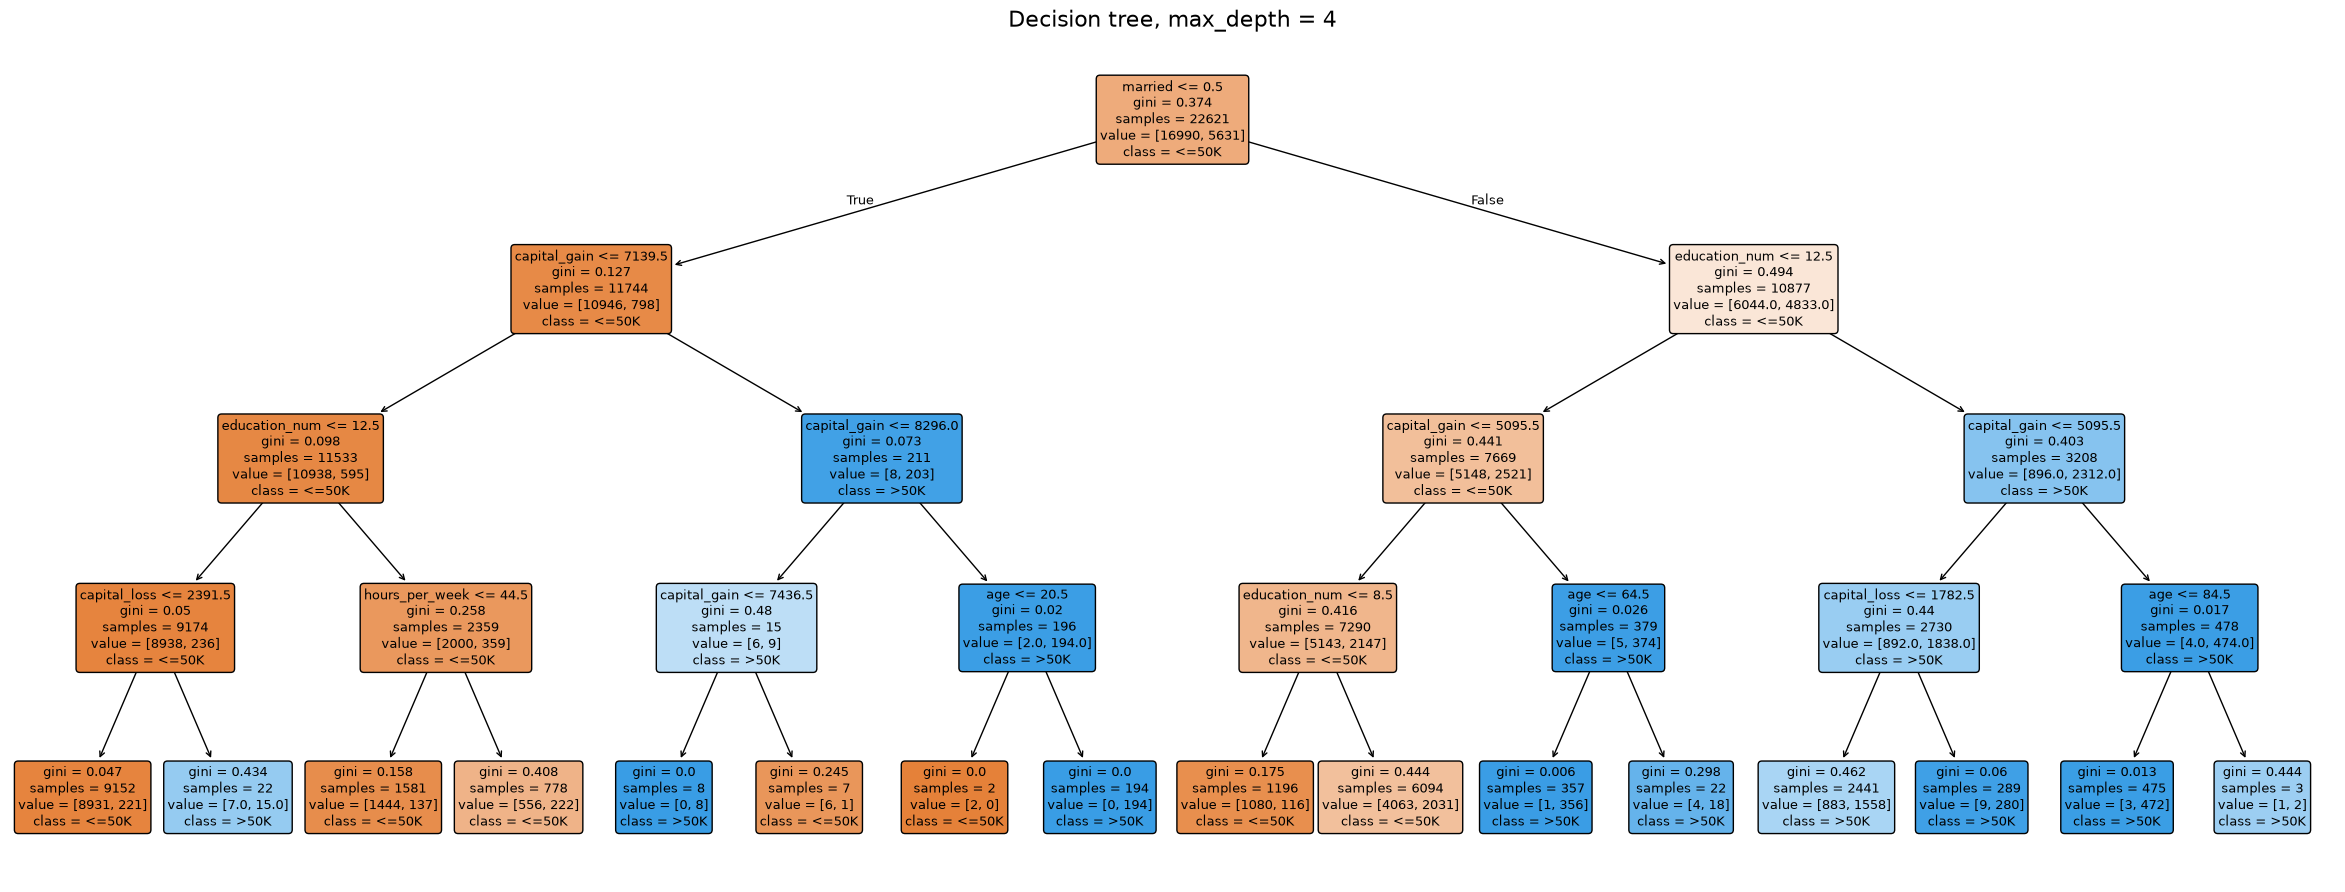

In [6]:
plt.figure(figsize=(30, 11))
plot_tree(tree_d4, feature_names=features, class_names=["<=50K", ">50K"],
          filled=True, rounded=True, fontsize=9)
plt.title("Decision tree, max_depth = 4", fontsize=16)
plt.show()

**What I see in the trees**

Both trees start the same way. The very first question is **"is this person married?"** That one split separates the data better than anything else: among unmarried people only about 7% earn over 50K, while among married people it's closer to 45%.

The interesting part is the second level, where **the two nodes don't split on the same attribute**:
- For **unmarried** people the tree asks about `capital_gain > 7139.5`. Almost nobody in this group earns >50K from a salary alone, so the only thing that really picks out the high earners is a big capital gain.
- For **married** people it asks about `education_num > 12.5`, which is roughly "has at least a bachelor's degree". This group is much more mixed, and education is what best separates the higher earners from the rest.

This happens because the tree is greedy and each node only looks at the people that reached it. At every node it tries every feature and threshold and keeps whichever one lowers the gini impurity the most *for that particular subset*. Different subsets of people have different "best questions", so nodes at the same level end up splitting on different attributes.

In the depth-4 tree a few things stand out:
- `capital_gain` shows up again and again at different thresholds. It's a very skewed feature (most people have 0), so the tree keeps slicing it.
- `age`, `hours_per_week` and `capital_loss` only appear near the bottom, where they fine-tune small groups.
- `is_male` is never used at all. Once marriage is known, sex adds very little extra information.
- Several bottom splits lead to two leaves with the **same class** (e.g. `age <= 64.5` → both ">50K"). As we saw in class, these splits don't change any prediction. The tree makes them only because they make the nodes purer.

## 4. Effect of depth on bias and variance
To see the trade-off clearly, we grow trees from depth 1 up to 20 and also one with no depth limit, then compare train and test accuracy.

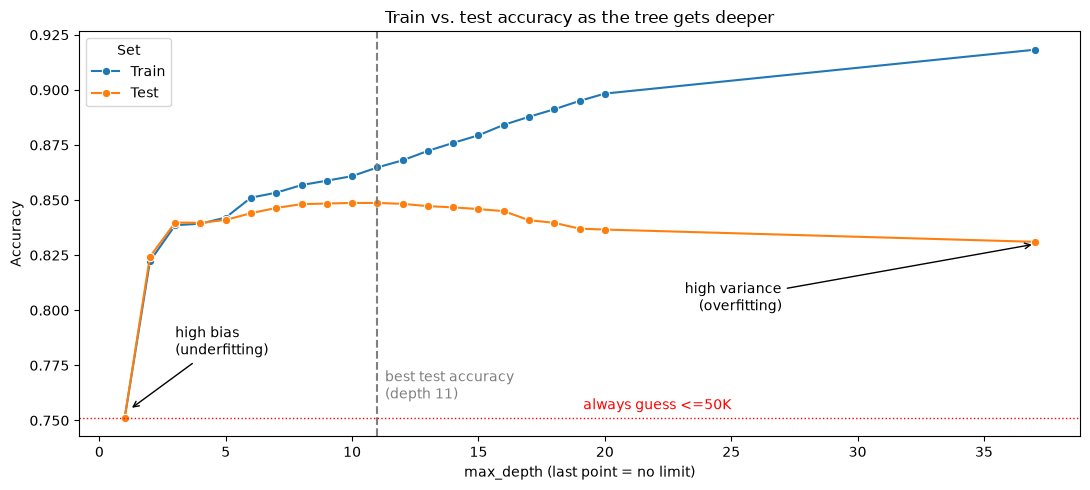

Depth,1,2,3,4,5,6,7,8,9,10,...,12,13,14,15,16,17,18,19,20,37
Leaves,2,4,8,16,29,49,76,121,184,270,...,521,692,891,1095,1308,1526,1727,1936,2133,3261


In [7]:
depths = list(range(1, 21)) + [None]
rows = []
for d in depths:
    t = DecisionTreeClassifier(max_depth=d, random_state=42).fit(X_train, y_train)
    label = d if d is not None else t.get_depth()   # unlimited tree: use its real depth
    rows.append({"Depth": label, "Set": "Train", "Accuracy": accuracy_score(y_train, t.predict(X_train)), "Leaves": t.get_n_leaves()})
    rows.append({"Depth": label, "Set": "Test",  "Accuracy": accuracy_score(y_test,  t.predict(X_test)),  "Leaves": t.get_n_leaves()})
depth_df = pd.DataFrame(rows)

best = depth_df[depth_df.Set == "Test"].sort_values("Accuracy", ascending=False).iloc[0]

plt.figure(figsize=(11, 5))
ax = sns.lineplot(data=depth_df, x="Depth", y="Accuracy", hue="Set", marker="o",
                  palette={"Train": "tab:blue", "Test": "tab:orange"})
ax.axvline(best.Depth, color="gray", ls="--")
ax.text(best.Depth + 0.3, 0.76, f"best test accuracy\n(depth {int(best.Depth)})", color="gray")
ax.axhline(1 - y_test.mean(), color="red", ls=":", lw=1)
ax.text(25, 1 - y_test.mean() + 0.004, "always guess <=50K", color="red", ha="right")
ax.annotate("high bias\n(underfitting)", xy=(1.2, 0.755), xytext=(3, 0.78),
            arrowprops=dict(arrowstyle="->"))
ax.annotate("high variance\n(overfitting)", xy=(depth_df.Depth.max(), 0.83), xytext=(27, 0.80),
            arrowprops=dict(arrowstyle="->"), ha="right")
ax.set_title("Train vs. test accuracy as the tree gets deeper")
ax.set_xlabel("max_depth (last point = no limit)")
plt.tight_layout()
plt.show()

leaves = depth_df[depth_df.Set == "Test"][["Depth", "Leaves"]].set_index("Depth").T
leaves

**Bias vs. variance**

- **Shallow trees have high bias.** With depth 1 the tree only asks "married or not?", and it predicts "<=50K" on both sides. Its accuracy (75%) is exactly what you'd get by always guessing "<=50K". The model is just too simple to capture the pattern, and train and test accuracy are basically the same. That's the classic sign of underfitting.
- **Moving deeper helps at first.** Depth 2 already jumps to about 82%, and test accuracy keeps creeping up until it peaks around depth 10–11 (~85%).
- **Past that, variance takes over.** Train accuracy keeps climbing (about 92% with no limit), but test accuracy starts to *drop*. The unlimited tree is 37 levels deep with over 3,000 leaves, many of them holding only a handful of people. It's memorizing quirks of the training set rather than learning general rules, so it has low bias but high variance. A slightly different training sample would give a very different tree.

So a moderate depth is the sweet spot. For the comparison with the neural networks I use the **depth-4 tree**: it's within 1% of the best test accuracy and still small enough to read.

## 5. How well do the trees perform?
We compare the depth-2 tree, the depth-4 tree, and an unlimited tree (to show what overfitting looks like in the metrics).

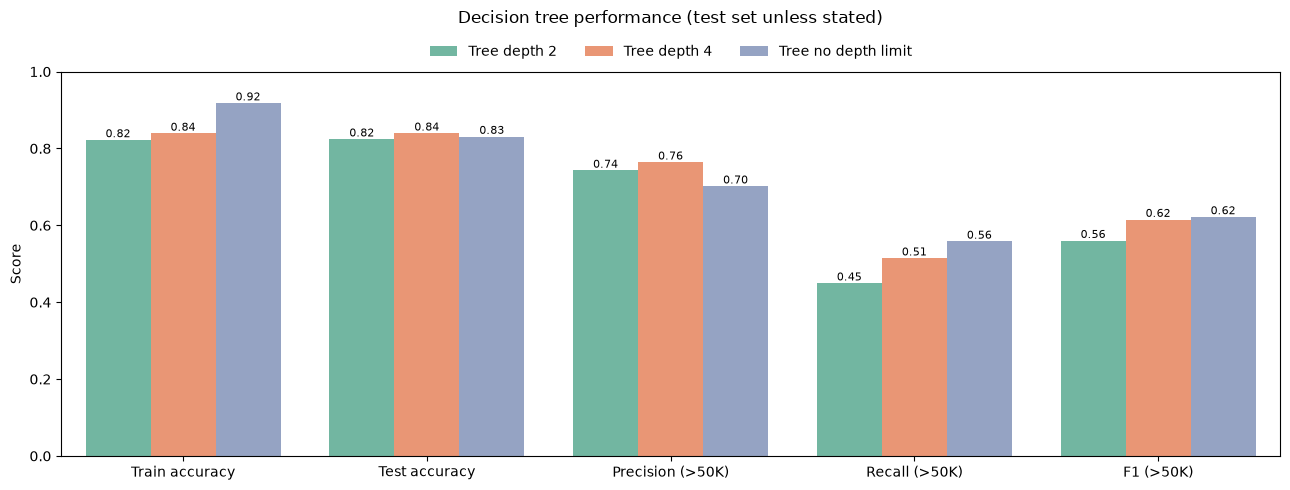

In [8]:
tree_full = DecisionTreeClassifier(random_state=42).fit(X_train, y_train)

tree_models = {
    "Tree depth 2":          tree_d2,
    "Tree depth 4":          tree_d4,
    "Tree no depth limit":   tree_full,
}
plot_metrics(tree_models, X_train, X_test, "Decision tree performance (test set unless stated)")

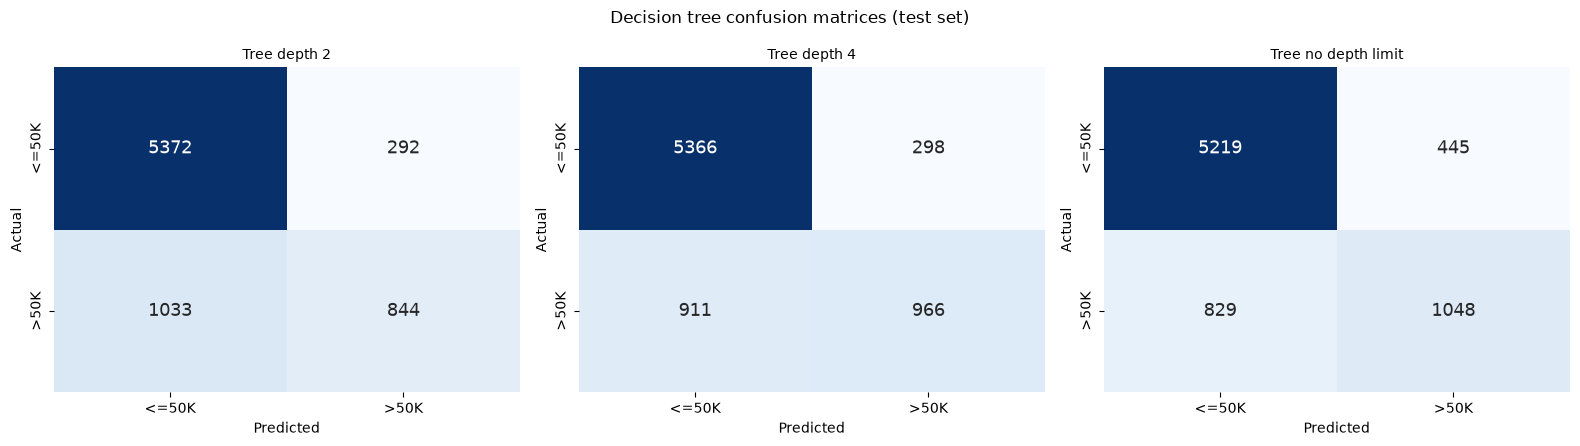

In [9]:
plot_confusion(tree_models, X_test, "Decision tree confusion matrices (test set)")

**What the metrics show**

- **Depth 2** gets 82.4% test accuracy but only catches **45%** of the real high earners. With just 4 leaves it can only say ">50K" for two broad groups (unmarried with big capital gains, and married with a degree), so it misses everyone else. That's bias showing up in the metrics.
- **Depth 4** is better across the board: 84.0% accuracy, the best precision (0.76), and recall up to 52%. The extra splits let it find more high earners without making many more false alarms. Its train and test scores are practically identical (83.9% vs. 84.0%), so it isn't overfitting at all.
- **No depth limit** is where variance shows up. It scores **91.8% on training data but only 83.1% on the test set**, a gap of almost 9 points, and its test accuracy is actually *worse* than the depth-4 tree's. It does have slightly higher recall (56%) because it's willing to call more people ">50K", but it pays for that with many more false alarms: 445 low earners wrongly flagged vs. 298 for depth 4, which drags its precision down to 0.70.

In every confusion matrix the bottom-left box (real high earners predicted as <=50K) is the big problem. That's the same weakness the neural networks have below.

## 6. Which features does the tree rely on?
A feature's importance = how much it reduces gini impurity in total across all of its splits (normalized to sum to 1).

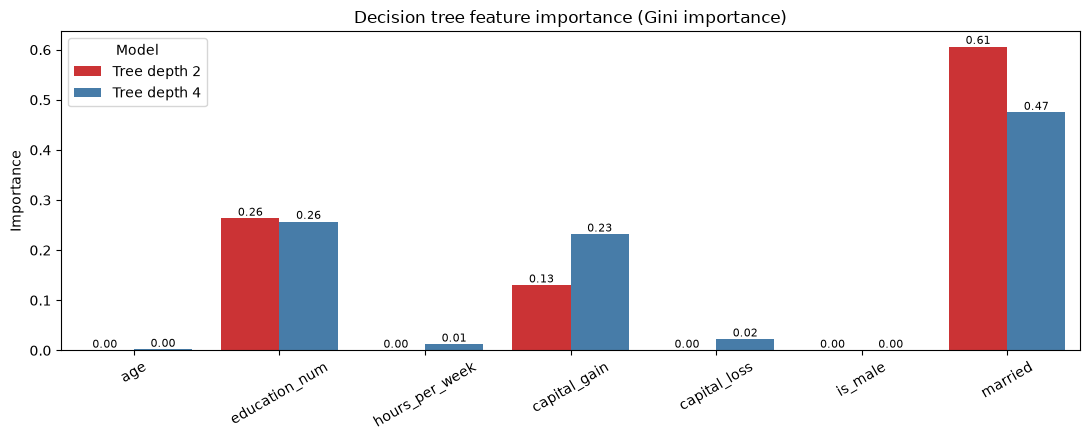

In [10]:
tree_imp = pd.DataFrame({"Tree depth 2": tree_d2.feature_importances_,
                         "Tree depth 4": tree_d4.feature_importances_},
                        index=features)
tree_imp_long = tree_imp.reset_index().melt(id_vars="index", var_name="Model", value_name="Importance")

plt.figure(figsize=(11, 4.5))
ax = sns.barplot(data=tree_imp_long, x="index", y="Importance", hue="Model", palette="Set1")
for bars in ax.containers:
    ax.bar_label(bars, fmt="%.2f", fontsize=8)
ax.set_xlabel("")
ax.set_title("Decision tree feature importance (Gini importance)")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

**What I see**

`married` is by far the most important feature in both trees (about 61% at depth 2 and 48% at depth 4), followed by `education_num` and `capital_gain`. The depth-2 tree uses *only* those three features, and everything else gets exactly zero. Going to depth 4 lets a few more features in (`capital_loss`, `hours_per_week`, `age`), but only with tiny importances, because they're only used to fine-tune small groups near the bottom of the tree. `is_male` stays at zero in both trees.

---
# Part 2 – Neural Networks

## 7. Why scaling matters here
The networks use the same 7 features and the same split as the trees, but with the standardized inputs (`X_train_s`, `X_test_s`) from section 2. Without scaling, `capital_gain` (values up to 99,999) would swamp `is_male` (0 or 1), and the network would have a hard time learning.

## 8. Train three architectures
| Name | Hidden layers |
|---|---|
| A | 1 layer: 4 nodes |
| B | 2 layers: 8, 4 nodes |
| C | 3 layers: 12, 8, 4 nodes |

In [11]:
architectures = {
    "A: 1 hidden layer (4)":          (4,),
    "B: 2 hidden layers (8, 4)":      (8, 4),
    "C: 3 hidden layers (12, 8, 4)":  (12, 8, 4),
}

models = {}
for name, layers in architectures.items():
    mlp = MLPClassifier(hidden_layer_sizes=layers, max_iter=1000, random_state=42)
    mlp.fit(X_train_s, y_train)
    models[name] = mlp

### How well does each network do?
Accuracy alone can be misleading here because only ~25% of people earn >50K.
So we also look at **precision**, **recall** and **F1** for the >50K class.

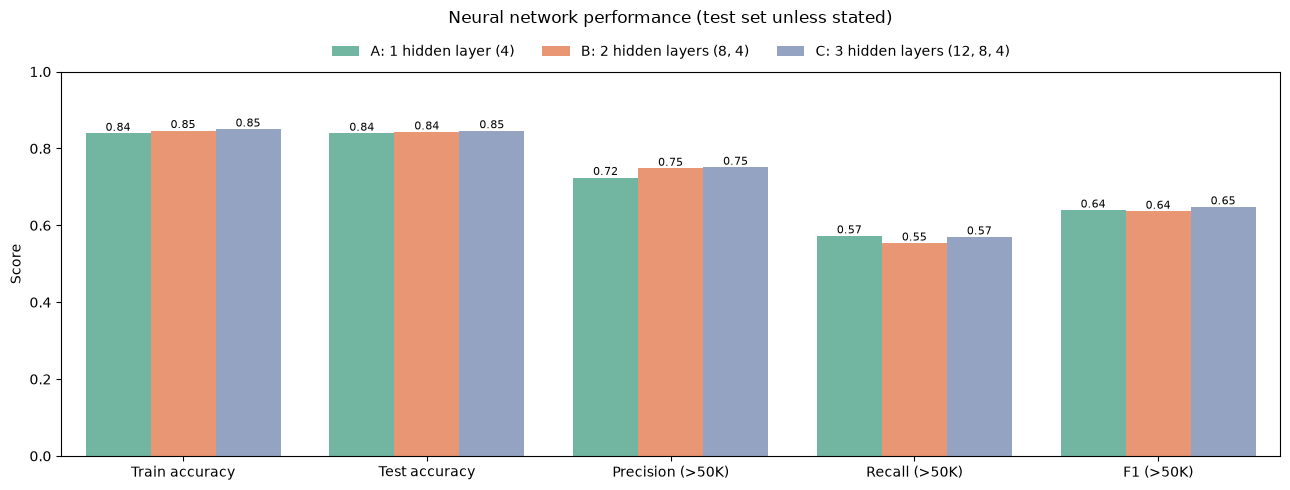

In [12]:
plot_metrics(models, X_train_s, X_test_s, "Neural network performance (test set unless stated)")

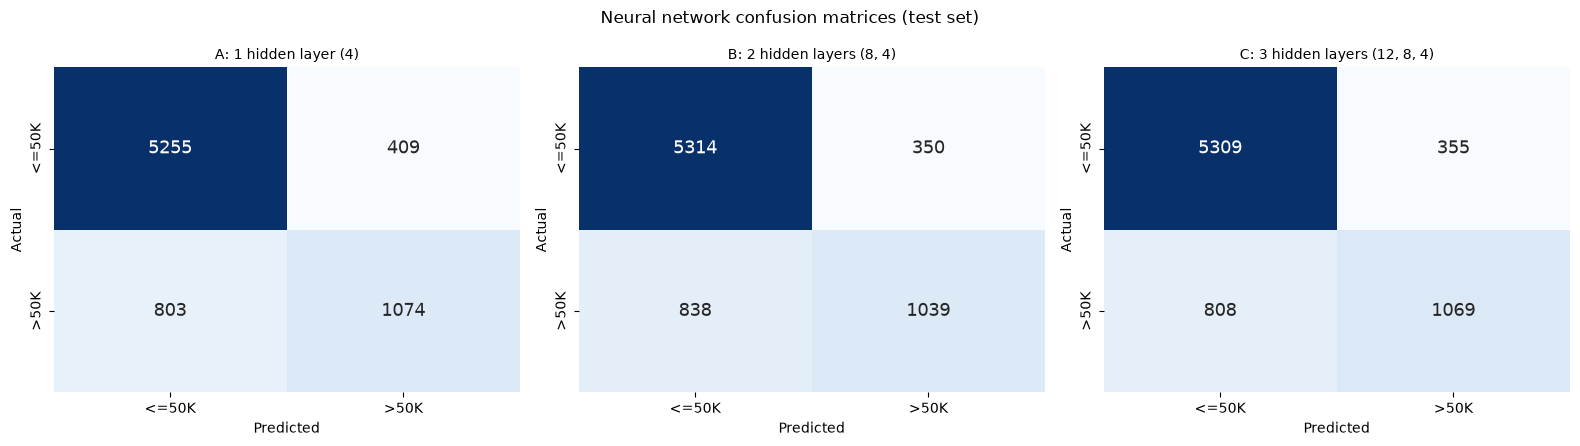

In [13]:
plot_confusion(models, X_test_s, "Neural network confusion matrices (test set)")

## 9. Visualize each architecture
- **Blue** edge = positive weight, **red** edge = negative weight
- Thicker / darker edge = larger |weight|
- Input nodes are labeled with the feature names

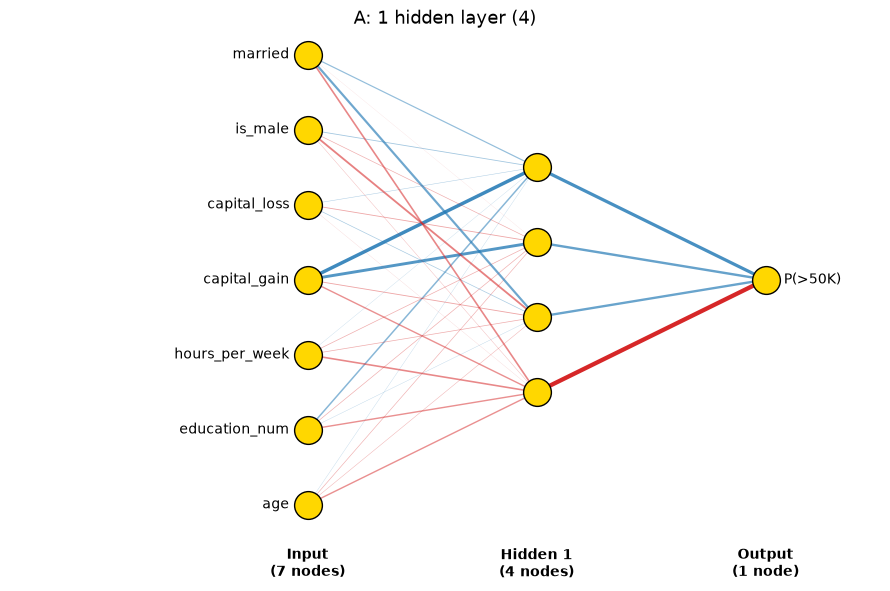

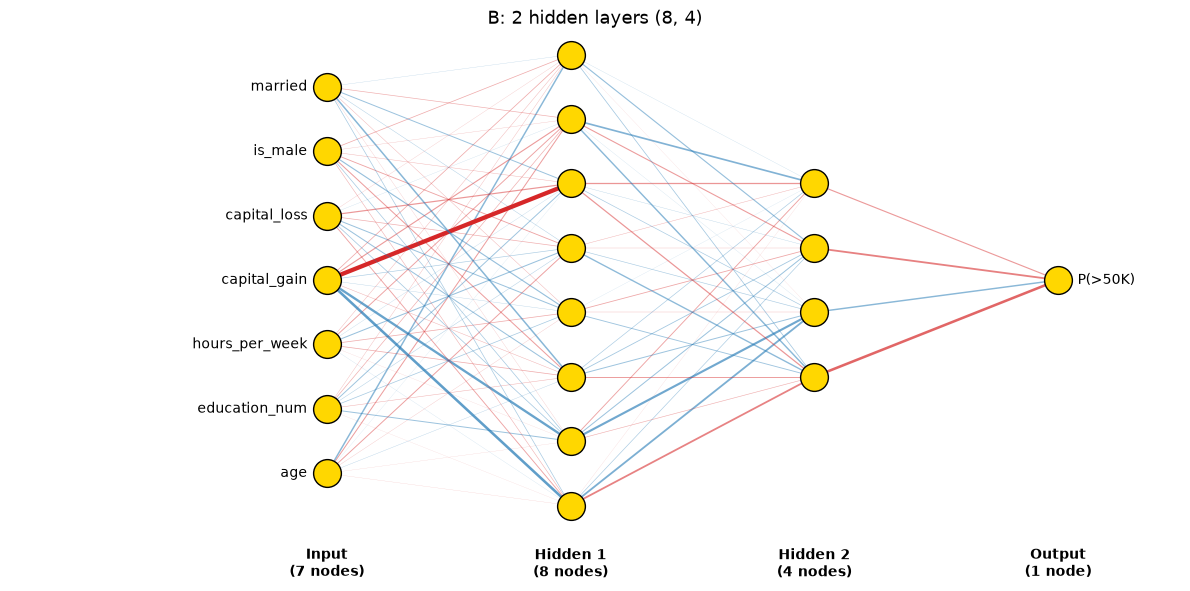

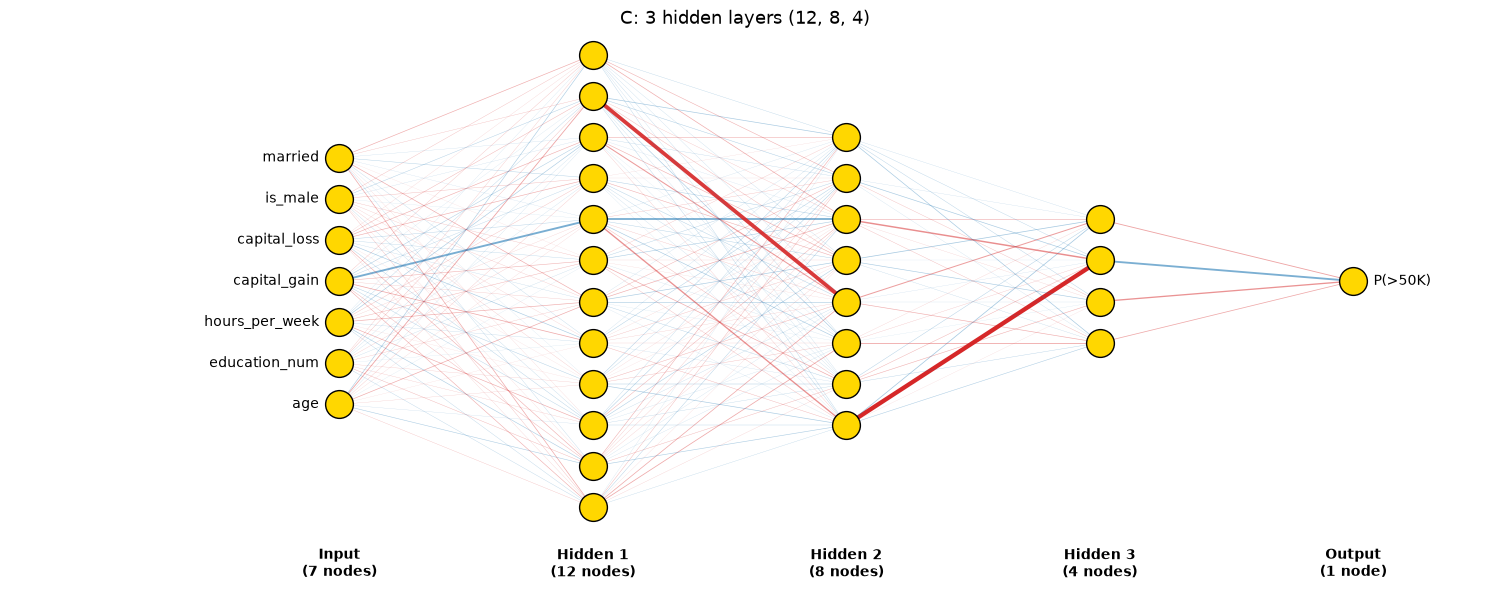

In [14]:
def draw_network(mlp, feature_names, title):
    layer_sizes = [mlp.coefs_[0].shape[0]] + [w.shape[1] for w in mlp.coefs_]
    max_size = max(layer_sizes)

    # (x, y) position of every node, centered vertically
    pos = []
    for L, n in enumerate(layer_sizes):
        ys = np.linspace(0, 1, n) if n > 1 else [0.5]
        offset = (max_size - n) / (2 * max_size)
        pos.append([(L, offset + y_ * (n - 1) / max_size) for y_ in ys])

    fig, ax = plt.subplots(figsize=(3 * len(layer_sizes), 6))
    w_max = max(np.abs(w).max() for w in mlp.coefs_)

    # edges
    for L, W in enumerate(mlp.coefs_):
        for i in range(W.shape[0]):
            for j in range(W.shape[1]):
                w = W[i, j]
                (x1, y1), (x2, y2) = pos[L][i], pos[L + 1][j]
                ax.plot([x1, x2], [y1, y2],
                        color="tab:blue" if w > 0 else "tab:red",
                        linewidth=3 * abs(w) / w_max + 0.1,
                        alpha=0.3 + 0.7 * abs(w) / w_max, zorder=1)
    # nodes
    for layer in pos:
        for (x, y_) in layer:
            ax.scatter(x, y_, s=400, color="gold", edgecolor="black", zorder=2)

    # labels
    for i, name in enumerate(feature_names):
        x, y_ = pos[0][i]
        ax.text(x - 0.08, y_, name, ha="right", va="center", fontsize=10)
    x, y_ = pos[-1][0]
    ax.text(x + 0.08, y_, "P(>50K)", ha="left", va="center", fontsize=10)

    names = ["Input"] + [f"Hidden {k+1}" for k in range(len(layer_sizes) - 2)] + ["Output"]
    for L, n in enumerate(names):
        ax.text(L, -0.08, f"{n}\n({layer_sizes[L]} node{'s' if layer_sizes[L] > 1 else ''})", ha="center", va="top",
                fontsize=10, weight="bold")

    ax.set_title(title, fontsize=13)
    ax.set_xlim(-1.3, len(layer_sizes) - 0.5)
    ax.axis("off")
    plt.tight_layout()
    plt.show()

for name, mlp in models.items():
    draw_network(mlp, features, name)

**What I see in the diagrams**

Network A is small enough that you can actually follow it by eye. The thickest lines leaving the inputs come from `capital_gain`, and they feed two hidden nodes that both push the output toward ">50K" (blue lines into the output). One hidden node is the opposite: almost all of its incoming edges are red, and it connects to the output with the thickest red line in the picture. Since a hidden node only fires when its total input is positive, all those red edges mean it switches on when someone is *below average* on age, education, hours and marital status. Then it pushes the prediction toward "<=50K". So it acts like a "probably low income" detector. Another node gets a strong blue line from `married`, which matches the common pattern that married people in this dataset are much more likely to earn over 50K.

Networks B and C are a different story. With 8 and then 12 nodes in the first layer, most edges are thin and faint, and the strong ones are scattered around. You can still spot `capital_gain` with one of the thickest edges in each, but it's very hard to trace how any single input ends up affecting the output. The extra nodes didn't buy much accuracy, but they cost a lot of readability.

## 10. First-layer weights as a heatmap
Row = input feature, column = hidden neuron. Each column shows what that neuron "looks at", like a small learned rule.

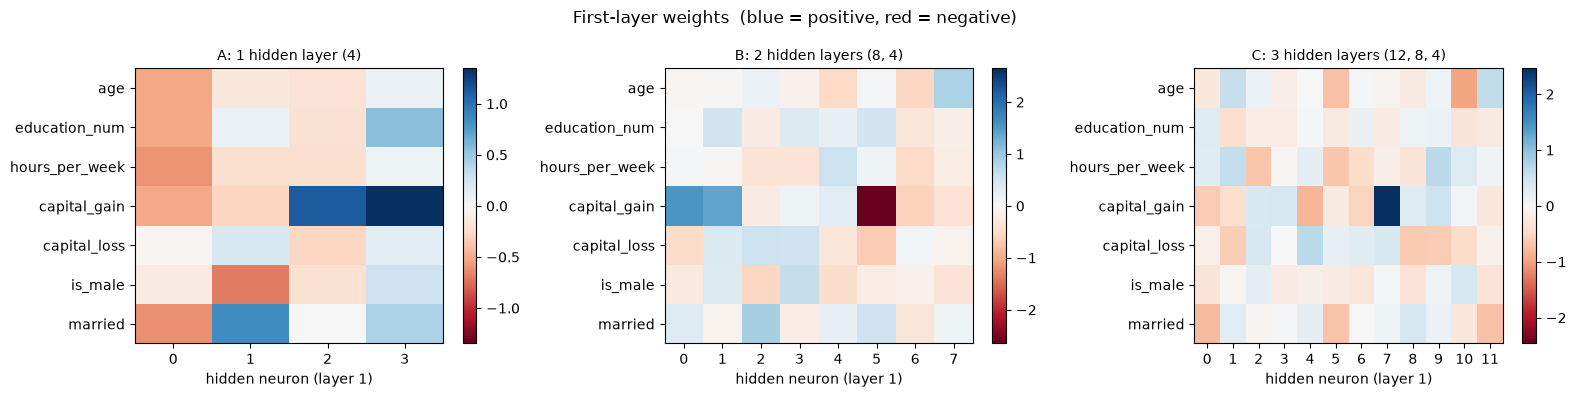

In [15]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, (name, mlp) in zip(axes, models.items()):
    W = mlp.coefs_[0]
    lim = np.abs(W).max()
    im = ax.imshow(W, cmap="RdBu", vmin=-lim, vmax=lim, aspect="auto")
    ax.set_yticks(range(len(features)))
    ax.set_yticklabels(features)
    ax.set_xticks(range(W.shape[1]))
    ax.set_xlabel("hidden neuron (layer 1)")
    ax.set_title(name, fontsize=10)
    fig.colorbar(im, ax=ax)
plt.suptitle("First-layer weights  (blue = positive, red = negative)")
plt.tight_layout()
plt.show()

**What I see in the heatmaps**

For network A each column is easy to read:
- **Neuron 0** is light red across the board, so it reacts to people who are below average on most things (the "low income" node from the diagram).
- **Neuron 1** is blue for `married` but red for `is_male`, so it fires mostly for married women. That's a small group, but in this data married women ("wife") earn >50K at a much higher rate than women overall, so the network seems to have carved out a node just for them.
- **Neurons 2 and 3** are dark blue on `capital_gain`. Neuron 3 also leans a bit positive on education and being married. These are the "high income" nodes.

In B and C, almost every cell is pale, and there's usually just one strong cell per column. The darkest cells in both are still in the `capital_gain` row: deep red in B (neuron 5) and deep blue in C (neuron 7). The sign alone doesn't tell you which way the effect goes in the end, because the later layers can flip it. But it confirms that capital gain is the one input every network latches onto. The other features get spread thinly across many nodes, which is why the deeper networks are so much harder to interpret than network A.

---
# Comparison: Edge Weights vs. Decision Trees

## 11. Do the network's edge weights agree with the decision tree?
We give every feature an importance score from each model and compare them:
- **Tree:** Gini importance from the depth-4 tree.
- **Network, first layer:** total |weight| on the edges leaving each input (the thick lines in the diagrams).
- **Network, full path:** multiply the weights along every path from an input to the output and add them up. This lets positive and negative paths cancel out, so it shows the input's overall effect.

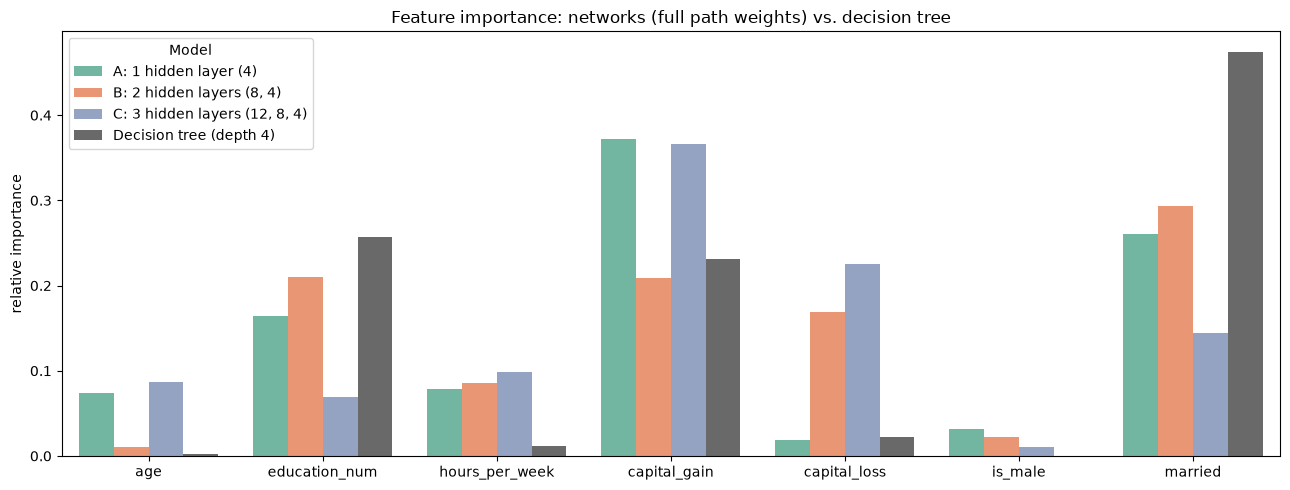

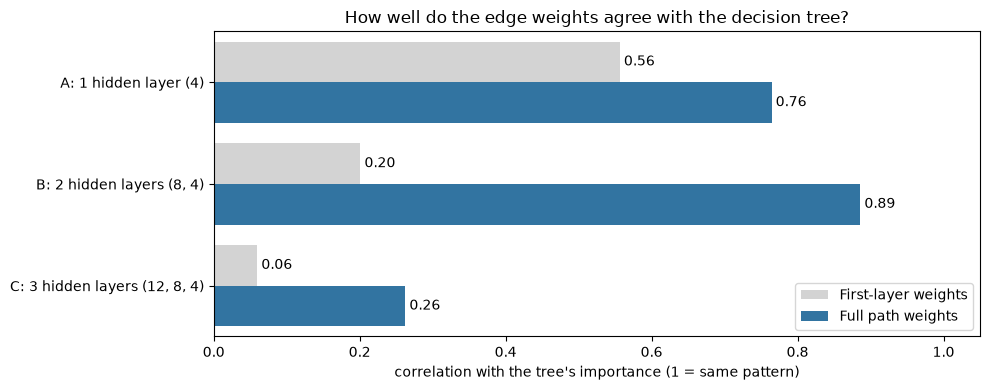

In [16]:
def first_layer_importance(mlp):
    s = np.abs(mlp.coefs_[0]).sum(axis=1)
    return s / s.sum()

def path_importance(mlp):
    P = mlp.coefs_[0]
    for W in mlp.coefs_[1:]:
        P = P @ W                      # weights multiplied along every path to the output
    P = np.abs(P.ravel())
    return P / P.sum()

tree_imp = tree_d4.feature_importances_

# Chart 1: path importance of each network next to the tree
compare = pd.DataFrame({n: path_importance(m) for n, m in models.items()}, index=features)
compare["Decision tree (depth 4)"] = tree_imp
long = compare.reset_index().melt(id_vars="index", var_name="Model", value_name="Importance")

plt.figure(figsize=(13, 5))
sns.barplot(data=long, x="index", y="Importance", hue="Model",
            palette=sns.color_palette("Set2", 3) + ["dimgray"])
plt.xlabel("")
plt.ylabel("relative importance")
plt.title("Feature importance: networks (full path weights) vs. decision tree")
plt.tight_layout()
plt.show()

# Chart 2: one correlation number per network
corr = pd.DataFrame([
    {"Network": n, "Measure": measure, "r": np.corrcoef(fn(m), tree_imp)[0, 1]}
    for n, m in models.items()
    for measure, fn in [("First-layer weights", first_layer_importance),
                        ("Full path weights",   path_importance)]])

plt.figure(figsize=(10, 4))
ax = sns.barplot(data=corr, x="r", y="Network", hue="Measure", palette=["lightgray", "tab:blue"])
for bars in ax.containers:
    ax.bar_label(bars, fmt="%.2f", padding=3)
ax.set_xlim(0, 1.05)
ax.set_ylabel("")
ax.set_xlabel("correlation with the tree's importance (1 = same pattern)")
ax.set_title("How well do the edge weights agree with the decision tree?")
ax.legend(loc="lower right")
plt.tight_layout()
plt.show()

**What we see**

- **Looking only at the first layer, the match is weak** (r = 0.56, 0.20, 0.06). Every network's thickest edges come from `capital_gain`, while the tree's top feature is `married`.
- **Following the weights all the way to the output, networks A and B match the tree well** (r = 0.76 and 0.89). `married`, `education_num` and `capital_gain` come out on top, just like in the tree, and all three push toward >50K in both models.
- **`is_male` is a good example.** It has fairly thick first-layer edges, but its paths mostly cancel out by the time they reach the output. That fits the tree, which never splits on it: 88% of married people in this data are men, so once the tree knows `married`, sex adds almost nothing.
- **Network C doesn't line up with the tree either way** (r = 0.26 at best). With three hidden layers the signal gets mixed too much to read off the weights, even though its accuracy is just as good.

**In short:** the edge weights and the tree agree on what matters (marital status, education and capital gain), but you only see it clearly in the smaller networks and when you follow the weights all the way to the output.

---
## 12. Discussion

**Decision trees.** The depth-2 tree is easy to read but too simple (high bias): it misses more than half of the high earners. The depth-4 tree hits 84% test accuracy with almost no gap between train and test. Letting the tree grow with no limit pushes train accuracy to 92% but drops test accuracy to 83%, which is classic high variance. The tree always splits on `married` first. Then nodes at the same level split on different features (`capital_gain` for unmarried people, `education_num` for married people), because each node picks the best split for its own group of people.

**Neural networks.** Adding layers barely helped: test accuracy went from 83.9% (one layer of 4 nodes) to 84.6% (three layers), while the bigger networks took longer to train and were much harder to interpret. All three catch only about 55–57% of the high earners, so the limit seems to be the 7 features, not the model size.

**Trees vs. networks.** Both reach about the same accuracy and rely on the same core features: marital status, education and capital gain. The edge weights of the small networks line up well with the tree once you follow them to the output. The tree's advantage is that it gives you readable rules directly ("married + bachelor's degree or more → likely >50K"), while the networks need extra work to interpret and quickly turn into a black box as they get deeper. For this dataset, a moderate-depth tree is the better choice if you need to explain your predictions. A small network performs about the same.